# Interaction generation

Fit on training readings only. Affinity measures historical activity compatibility, not explicit preference or flexibility.

Run the complete pipeline first. Select the project virtual environment as the notebook kernel.

In [1]:
from pathlib import Path
import sys
ROOT = Path.cwd() if (Path.cwd() / 'src').exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT))
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt


In [2]:
from src.data import load_meter
from src.preprocessing import AffinityBuilder
train = load_meter(ROOT/'data/processed/train.csv')
builder = AffinityBuilder().fit(train)
interactions = builder.transform(train)
interactions.head()

Out[0]: 
  household_id  item  mean_kwh  ...  consistency  affinity  confidence
0        H0000     0  0.083539  ...     0.735106  0.196487    7.666667
1        H0000     1  0.081058  ...     0.742841  0.140284    5.761905
2        H0000     2  0.087176  ...     0.761125  0.186516    7.190476
3        H0000     3  0.079943  ...     0.745292  0.182222    7.190476
4        H0000     4  0.081495  ...     0.768037  0.199409    7.666667

[5 rows x 9 columns]


Out[0]: Text(0.5, 0, 'Context-slot item')


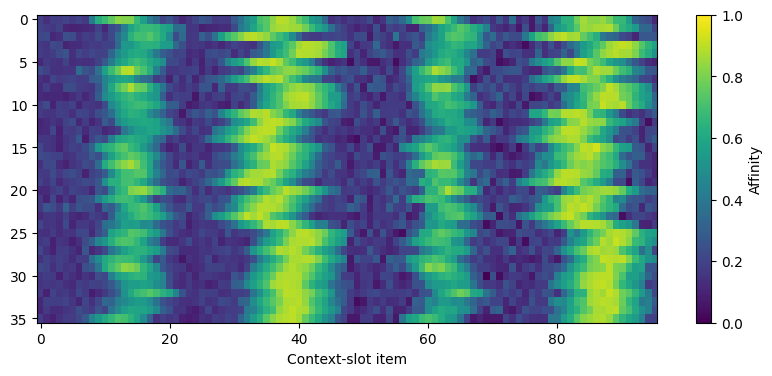

In [3]:
matrix = interactions.pivot(index='household_id',columns='item',values='affinity')
plt.figure(figsize=(10,4)); plt.imshow(matrix,aspect='auto',vmin=0,vmax=1); plt.colorbar(label='Affinity'); plt.xlabel('Context-slot item');